<a href="https://colab.research.google.com/github/Magdalewa/podstawyAI/blob/main/AI_przestrzen_stanow_BFS_DFS_Astar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [250]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0) zwykłe, "#" – przeszkoda (1), "?" - pole dostępne (3) piasek, "-" - pole dostępne (5) bagno
MAPA = [
    "..#....#......",
    "#-.........#.#",
    ".-.......#.#.#",
    ".-#......#.#..",
    "#?#......#.#..",
    ".?#......#.#.#",
    "#??##....#..##",
    ".???.........#",
    "#............#",
    "#.##..........",
]

grid = [[1 if ch == "#" else 3 if ch == "?" else 5 if ch == "-" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)
print(grid)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)
[[0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [1, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1], [0, 5, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1], [0, 5, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], [1, 3, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], [0, 3, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1], [1, 3, 3, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1], [0, 3, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [251]:
def get_neighbors(state):
    r, c = state

    moves = [
        (0, 1),   # prawo
        (1, 1),   # prawy dolny róg
        (1, 0),   # dół
        (1, -1),   # lewy dolny róg
        (0, -1),  # lewo
        (-1, -1),   # lewy górny róg
        (-1, 0),  # góra
        (-1, 1)   # prawy górny róg
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] != 1:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))
print("Sąsiedzi pola (2,4):", get_neighbors((2,4)))


Sąsiedzi startu: [(0, 1), (1, 1)]
Sąsiedzi pola (2,4): [(2, 5), (3, 5), (3, 4), (3, 3), (2, 3), (1, 3), (1, 4), (1, 5)]



## 2. Wizualizacja problemu


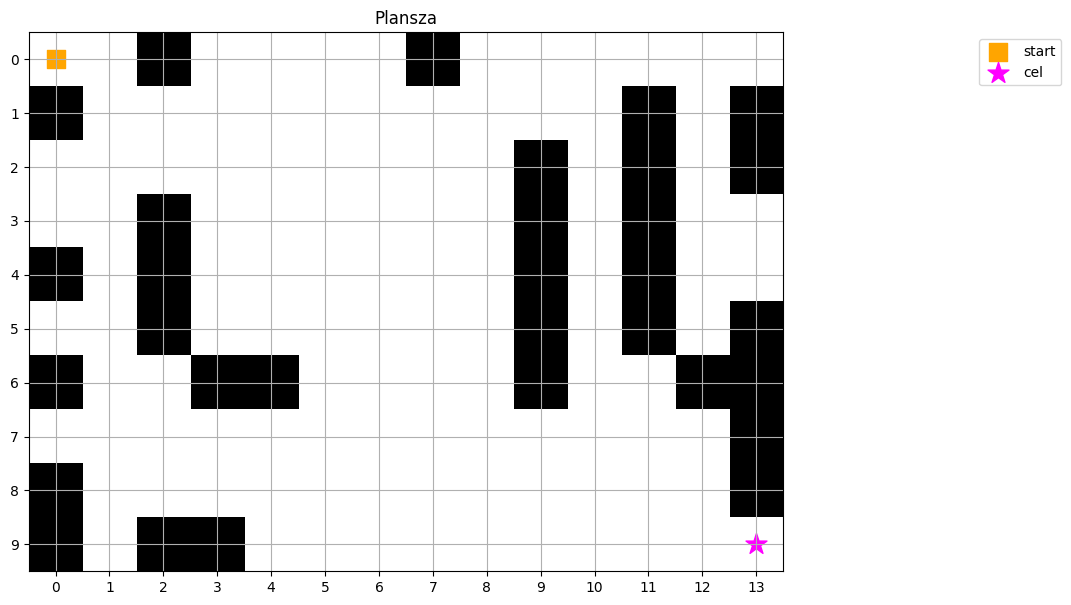

In [252]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell != 1 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki: 13
BFS - odwiedzone stany: 105
BFS - ścieżka: [(0, 0), (0, 1), (1, 2), (1, 3), (2, 4), (3, 5), (4, 6), (5, 7), (6, 8), (7, 9), (7, 10), (7, 11), (8, 12), (9, 13)]


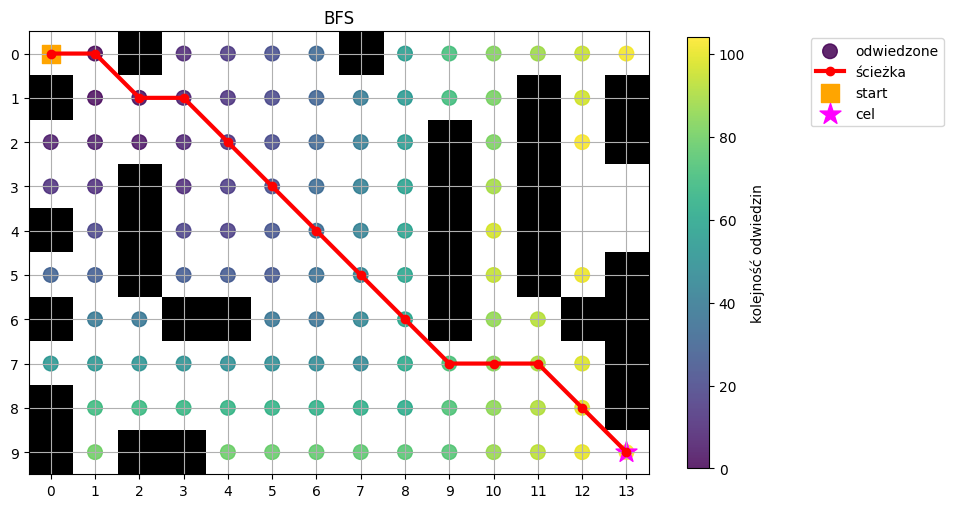

In [253]:
def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start]) ##kolejka, z ktorej bedziemy korzystac
    visited = {start} ## lista wszystkich stanow, ktore dodalismy do listy
    parent = {start: None} ## klucz:wartosc, sasiad, z ktorego dodalismy dany stand
    visit_order = [] ##lista odwiedzonych stanow - nie sciezka!

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")


BFS - długość ścieżki: 13
BFS - odwiedzone stany: 105
BFS - ścieżka: [(0, 0), (0, 1), (1, 2), (1, 3), (2, 4), (3, 5), (4, 6), (5, 7), (6, 8), (7, 9), (7, 10), (7, 11), (8, 12), (9, 13)]


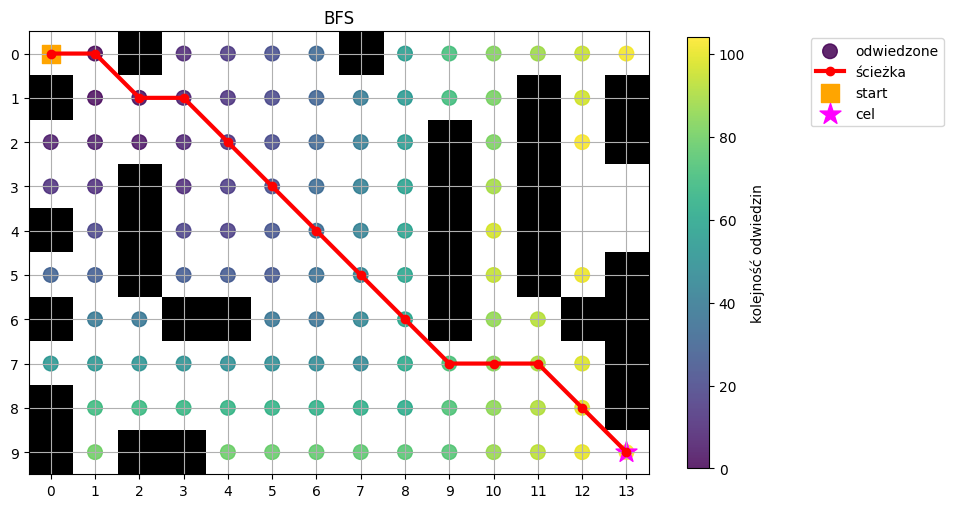

In [254]:
def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start]) ##kolejka, z ktorej bedziemy korzystac
    visited = {start} ## lista wszystkich stanow, ktore dodalismy do kolejki
    parent = {start: None} ## klucz:wartosc, sasiad, z ktorego dodalismy dany stand
    visit_order = [] ##lista odwiedzonych stanow - nie sciezka!

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")


### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?

ODP:
1. Gdybyśmy używali stosu to ciężko byłoby wyciągać elementy z początku.
2. Bo odwiedza stany w kolejności. BFS najpierw sprawdza wszystkie ścieżki o długości 1, potem 2, itd. Więc znajdziemy ścieżkę o długości n, to mamy pewność,że nie ma ścieżki o długości n-1, bo takie były już sprawdzone w poprzednim kroku.
3. Zużycie pamięci szybko rośnie, bo trzymamy w niej wszystkie odwiedzone stany.


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 99
DFS - odwiedzone stany: 109
DFS - ścieżka: [(0, 0), (1, 1), (0, 1), (1, 2), (0, 3), (1, 3), (0, 4), (1, 4), (0, 5), (1, 5), (0, 6), (1, 6), (2, 5), (2, 4), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (4, 1), (5, 0), (6, 1), (5, 1), (6, 2), (5, 3), (4, 4), (3, 5), (2, 6), (1, 7), (0, 8), (1, 8), (0, 9), (1, 9), (0, 10), (1, 10), (0, 11), (1, 12), (2, 12), (3, 12), (4, 12), (3, 13), (4, 13), (5, 12), (6, 11), (5, 10), (6, 10), (7, 9), (6, 8), (5, 8), (4, 8), (3, 8), (2, 8), (2, 7), (3, 6), (4, 5), (3, 4), (3, 3), (4, 3), (5, 4), (6, 5), (5, 6), (4, 7), (3, 7), (4, 6), (5, 5), (6, 6), (5, 7), (6, 7), (7, 6), (7, 5), (7, 4), (7, 3), (7, 2), (7, 1), (7, 0), (8, 1), (9, 1), (8, 2), (8, 3), (9, 4), (8, 5), (8, 4), (9, 5), (8, 6), (7, 7), (8, 7), (7, 8), (8, 8), (9, 7), (9, 8), (8, 9), (7, 10), (8, 10), (7, 11), (8, 11), (7, 12), (8, 12), (9, 11), (9, 12), (9, 13)]


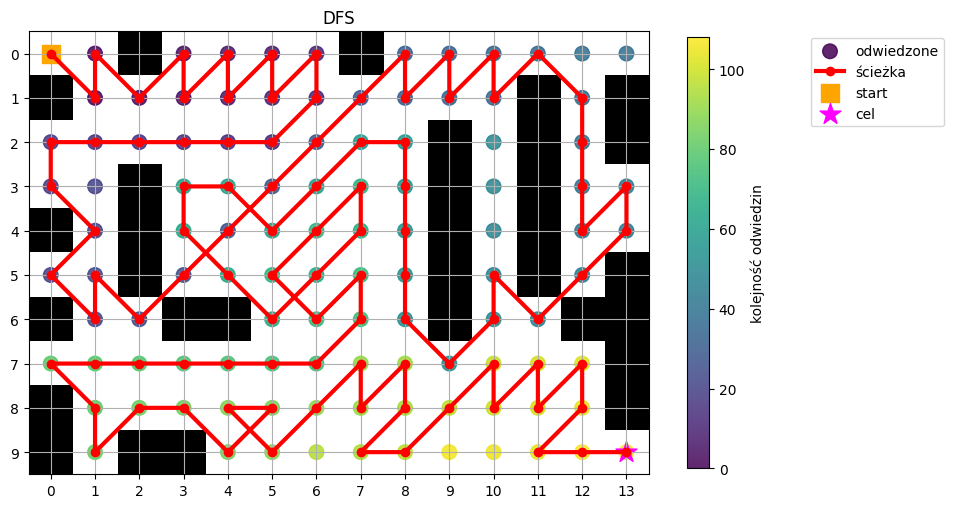

In [255]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [256]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81
(4, 6) Manhattan = 12 Euclidean = 8.6
(7, 10) Manhattan = 5 Euclidean = 3.61
(9, 12) Manhattan = 1 Euclidean = 1.0



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 13
Greedy - odwiedzone stany: 14


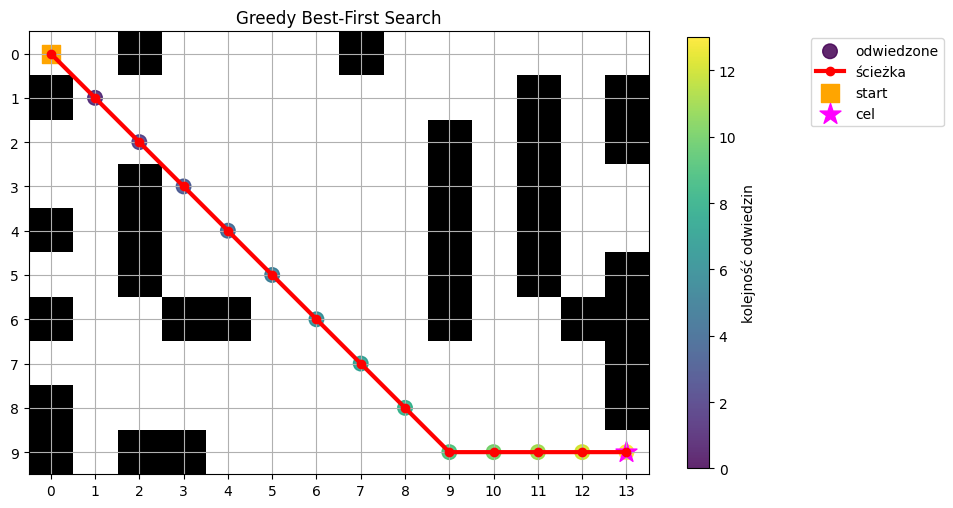

In [257]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


A* - koszt: 13
A* - odwiedzone stany: 14
A* - ścieżka: [(0, 0), (0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


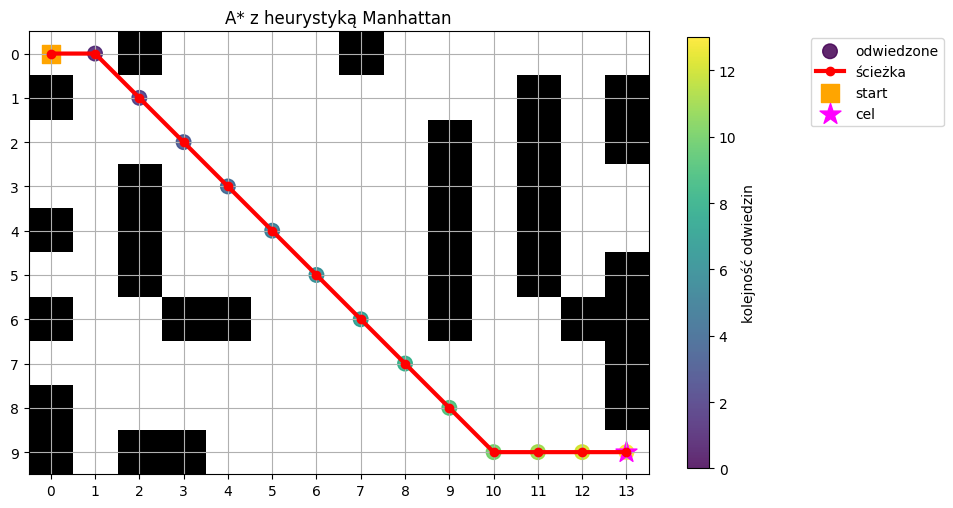

In [258]:
def get_cost(state):
    r, c = state

    if grid[r][c] == 0:
      return 1
    elif grid[r][c] == 3:
      return 3
    elif grid[r][c] == 5:
      return 5
    else:
      return 0

def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + get_cost(neighbor)

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [259]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")


Algorytm     Długość ścieżki    Odwiedzone stany
--------------------------------------------------
BFS          13                 105
DFS          99                 109
Greedy       13                 14
A*           13                 14



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [260]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 14
A* Euclidean - odwiedzone stany: 14



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [261]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))


A* z h=0 - odwiedzone stany: 107
BFS       - odwiedzone stany: 105



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 13
Odwiedzone stany: 14


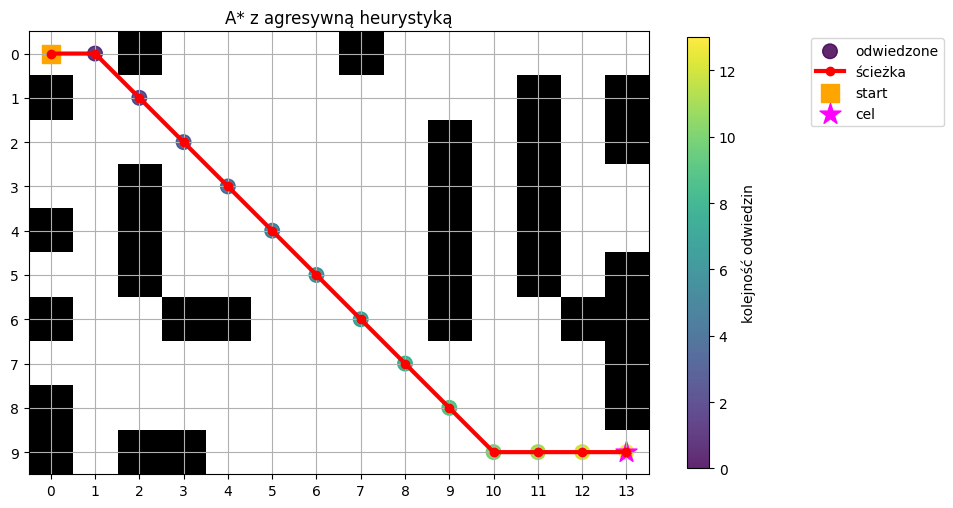

In [262]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)



# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

ODP: Zmieni się kolejność dodawania sąsiadów do kolejki, więc zmieni się też kolejność wyjmowania sąsiadów z kolejki. DFS znajdzie inną ścieżkę i zmieni się liczba odwiedzonych stanów.

---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

---

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def my_heuristic(a, b):
    ...
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

OPD:
1. Manhattan nie jest najlepszym wyborem, bo zawyża koszt przejścia po przekątnej - liczy go jako 2.
2. odleglosc Czebyszewa lub oktagonalna
3. A* wybierze 'wizualnie' najkrotsza trasę.

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

ODP: BFS nie gwarantuje najtańszej ścieżki - wybierze najkrótszą wizualnie, ale może ona być bardziej kosztowna, bo będzie prowadzić przez bagno/piasek - wejście na pole z bagnem koszuje tyle samo co przejście przez 5 zwykłych pól - trasa krótsza wizualnie nie musi być najtańsza.

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.

ODP: g(n) to faktyczny koszt przejścia do danego pola (wyliczona liczba), h(n) to szacowany koszt dojscia do celu (nie mamy pewności czy koszt przejścia będzie faktycznie taki).


In [263]:
def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)

def my_heuristic(a, b):
    return min(abs(a[0]-b[0]),abs(a[1]-b[1]))*2

examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2),
        "h(n)=0 =", round(zero_heuristic(state, goal), 2),
        "my_heuristic =", round(my_heuristic(state, goal), 2)
    )

astar_myheuristic_path, astar_myheuristic_visited, _ = astar(
    start,
    goal,
    heuristic=my_heuristic
)
print()
print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))
print("A* h(n)=0 - odwiedzone stany:", len(visited_h0))
print("A* my_heuristic - odwiedzone stany:", len(astar_myheuristic_visited))


(0, 0) Manhattan = 22 Euclidean = 15.81 h(n)=0 = 0 my_heuristic = 18
(4, 6) Manhattan = 12 Euclidean = 8.6 h(n)=0 = 0 my_heuristic = 10
(7, 10) Manhattan = 5 Euclidean = 3.61 h(n)=0 = 0 my_heuristic = 4
(9, 12) Manhattan = 1 Euclidean = 1.0 h(n)=0 = 0 my_heuristic = 0

A* Manhattan - odwiedzone stany: 14
A* Euclidean - odwiedzone stany: 14
A* h(n)=0 - odwiedzone stany: 107
A* my_heuristic - odwiedzone stany: 48


# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [264]:
# Miejsce na rozwiązanie zadania 8-puzzle.

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

# 1 funkcja generującą sąsiadów

def get_neighbors_puzzle(state):

    moves = [
        (0, 1),   # prawo
        (1, 0),   # dół
        (0, -1),  # lewo
        (-1, 0)  # góra
    ]

    neighbors = []

    for i in [0,1,2]:
      for j in [0,1,2]:
        if state[i*3+j] == 0:
          for dr, dc in moves:
            nr, nc = i + dr, j + dc
            if 0 <= nr < 3 and 0 <= nc < 3:
              a=list(state)
              for k in [0,1,2,3,4,5,6,7,8]:
                if k==i*3+j:
                  a[k]=state[nr*3+nc]
                elif k==nr*3+nc:
                  a[k]=0

              neighbors.append(tuple(a))

    return neighbors


print("Sąsiedzi startu:", get_neighbors_puzzle(start_puzzle))
print("Sąsiedzi goal:", get_neighbors_puzzle(goal_puzzle))

# 2. heurystyka Manhattan

def manhattan_puzzle(state, goal_puzzle):
    distance_sum = 0
    for i in [0,1,2]:
      for j in [0,1,2]:
        for k in [0,1,2]:
          for l in [0,1,2]:
            if state[i*3+j]==0:
              continue

            if state[i*3+j]==goal_puzzle[k*3+l]:
              distance_sum = distance_sum + abs(i - k) + abs(j - l)
    return distance_sum

examples = [(0, 2, 3, 1, 8, 6, 5, 4, 7), (0, 2, 3, 1, 8, 4, 5, 6, 7)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan_puzzle(state, goal_puzzle), 2)
    )

Sąsiedzi startu: [(2, 0, 4, 3, 6, 5, 7, 1, 8), (3, 2, 4, 0, 6, 5, 7, 1, 8)]
Sąsiedzi goal: [(1, 2, 3, 4, 5, 6, 7, 0, 8), (1, 2, 3, 4, 5, 0, 7, 8, 6)]
(0, 2, 3, 1, 8, 6, 5, 4, 7) Manhattan = 8
(0, 2, 3, 1, 8, 4, 5, 6, 7) Manhattan = 10


# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?
